# 01 · Análisis exploratorio de la demanda diaria

Este notebook describe el conjunto **Daily Demand Forecasting Orders (UCI 409)** y examina sus distribuciones y relaciones. Cada fila representa una observación diaria de una empresa logística brasileña. El archivo contiene 60 registros, 12 variables predictoras y una variable objetivo: `Total orders`.

El análisis es descriptivo: conserva los datos originales y documenta cuestiones que deberán resolverse antes de entrenar modelos. La copia local permite ejecutar el notebook sin consultar servicios externos. Fuente y condiciones de uso: [README de los datos](../data/README.md).

Ejecuta las celdas en orden, con el directorio de trabajo situado en `notebooks/`.

## Carga y estructura

`pd.read_csv` interpreta la primera fila como nombres de columnas. `shape` informa filas y columnas; `head()` permite verificar cómo se representa una observación. La ruta relativa conecta este notebook con la copia pública que se distribuye en `data/`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 100)

DATA_PATH = Path("../data/daily_demand.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError("Ejecuta el notebook desde notebooks/: falta ../data/daily_demand.csv")

df = pd.read_csv(DATA_PATH)
target = "Total orders"
print(f"Registros: {df.shape[0]} | Variables: {df.shape[1]}")
print(f"Predictoras: {df.shape[1] - 1} | Objetivo: {target}")
display(df.head())

Registros: 60 | Variables: 13
Predictoras: 12 | Objetivo: Total orders


,Week of the month,Day of the week,Non-urgent order,Urgent order,Order type A,Order type B,Order type C,Fiscal sector orders,Orders from the traffic controller sector,Banking orders (1),Banking orders (2),Banking orders (3),Total orders
0,1,4,316.307,223.270,61.543,175.586,302.448,0.000,65556,44914,188411,14793,539.577
1,1,5,128.633,96.042,38.058,56.037,130.580,0.000,40419,21399,89461,7679,224.675
2,1,6,43.651,84.375,21.826,25.125,82.461,1.386,11992,3452,21305,14947,129.412
3,2,2,171.297,127.667,41.542,113.294,162.284,18.156,49971,33703,69054,18423,317.120
4,2,3,90.532,113.526,37.679,56.618,116.220,6.459,48534,19646,16411,20257,210.517


## Tipos y significado de las variables

Un **tipo de almacenamiento** (`int64`, `float64`) indica cómo pandas guarda los valores. El **tipo estadístico** depende de su significado. Por eso los códigos de calendario se analizan como categorías, aunque estén almacenados como enteros.

- `Week of the month`: categoría ordinal; 1 corresponde a la primera semana y 5 a la quinta.
- `Day of the week`: categoría de calendario con ciclo semanal; se muestra en orden lunes–viernes, con códigos 2–6.
- Las columnas restantes son cuantitativas. `Order type A`, `B` y `C` contienen cantidades para cada tipo, no etiquetas de una única variable categórica.

La documentación no detalla qué define los tipos A/B/C ni los grupos bancarios, y no especifica de forma suficiente las unidades de los importes. Se conserva la escala publicada; los decimales no deben interpretarse automáticamente como fracciones de pedidos físicos.

In [2]:
cat_cols = ["Week of the month", "Day of the week"]
quant_cols = [column for column in df.columns if column not in cat_cols]

meanings = {
    "Week of the month": "Semana dentro del mes: primera a quinta.",
    "Day of the week": "Día laboral: códigos 2 (lunes) a 6 (viernes).",
    "Non-urgent order": "Cantidad asociada a pedidos no urgentes.",
    "Urgent order": "Cantidad asociada a pedidos urgentes.",
    "Order type A": "Cantidad de pedidos de tipo A; definición del tipo no detallada.",
    "Order type B": "Cantidad de pedidos de tipo B; definición del tipo no detallada.",
    "Order type C": "Cantidad de pedidos de tipo C; definición del tipo no detallada.",
    "Fiscal sector orders": "Cantidad asociada al sector fiscal; escala pendiente de aclaración.",
    "Orders from the traffic controller sector": "Cantidad asociada al sector de control de tráfico.",
    "Banking orders (1)": "Cantidad del grupo bancario 1; definición del grupo no detallada.",
    "Banking orders (2)": "Cantidad del grupo bancario 2; definición del grupo no detallada.",
    "Banking orders (3)": "Cantidad del grupo bancario 3; definición del grupo no detallada.",
    "Total orders": "Cantidad total diaria: variable objetivo del conjunto."
}

structure = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "tipo_estadistico": [
        "Cualitativa ordinal" if c == "Week of the month" else
        "Cualitativa de calendario" if c == "Day of the week" else
        "Cuantitativa" for c in df.columns
    ],
    "rol": ["Objetivo" if c == target else "Predictora" for c in df.columns],
    "valores_no_nulos": df.notna().sum(),
    "valores_distintos": df.nunique(),
    "significado": pd.Series(meanings)
})
structure.index.name = "variable"
display(structure)
print(f"Cualitativas: {len(cat_cols)} | Cuantitativas: {len(quant_cols)} (incluye el objetivo)")

,tipo_pandas,tipo_estadistico,rol,valores_no_nulos,valores_distintos,significado
variable,,,,,,
Week of the month,int64,Cualitativa ordinal,Predictora,60,5,Semana dentro del mes: primera a quinta.
Day of the week,int64,Cualitativa de calendario,Predictora,60,5,Día laboral: códigos 2 (lunes) a 6 (viernes).
Non-urgent order,float64,Cuantitativa,Predictora,60,60,Cantidad asociada a pedidos no urgentes.
Urgent order,float64,Cuantitativa,Predictora,60,60,Cantidad asociada a pedidos urgentes.
Order type A,float64,Cuantitativa,Predictora,60,60,Cantidad de pedidos de tipo A; definición del tipo no detallada.
Order type B,float64,Cuantitativa,Predictora,60,60,Cantidad de pedidos de tipo B; definición del tipo no detallada.
Order type C,float64,Cuantitativa,Predictora,60,60,Cantidad de pedidos de tipo C; definición del tipo no detallada.
Fiscal sector orders,float64,Cuantitativa,Predictora,60,48,Cantidad asociada al sector fiscal; escala pendiente de aclaración.
Orders from the traffic controller sector,int64,Cuantitativa,Predictora,60,60,Cantidad asociada al sector de control de tráfico.


Cualitativas: 2 | Cuantitativas: 11 (incluye el objetivo)


## Calidad inicial: faltantes, duplicados y códigos

Contar faltantes y filas repetidas permite describir la calidad de la copia recibida. Una fila duplicada completa no es lo mismo que dos días con igual demanda. Las comprobaciones se realizan antes de convertir códigos a categorías, para evitar que un valor inesperado se transforme silenciosamente en nulo. Aquí no se elimina ni imputa ninguna observación.

In [3]:
allowed_values = {
    "Week of the month": [1, 2, 3, 4, 5],
    "Day of the week": [2, 3, 4, 5, 6]
}

quality = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje_faltantes": 100 * df.isna().mean()
})
display(quality)
print("Filas duplicadas completas:", int(df.duplicated().sum()))
print("Valores infinitos:", int(np.isinf(df[quant_cols].to_numpy()).sum()))
for column, allowed in allowed_values.items():
    unexpected = sorted(df.loc[df[column].notna() & ~df[column].isin(allowed), column].unique())
    print(f"Códigos fuera del dominio en {column}: {unexpected}")
    if unexpected:
        raise ValueError(f"Revisar los códigos de {column} antes de continuar.")

,faltantes,porcentaje_faltantes
Week of the month,0,0.0
Day of the week,0,0.0
Non-urgent order,0,0.0
Urgent order,0,0.0
Order type A,0,0.0
Order type B,0,0.0
Order type C,0,0.0
Fiscal sector orders,0,0.0
Orders from the traffic controller sector,0,0.0
Banking orders (1),0,0.0


Filas duplicadas completas: 0
Valores infinitos: 0
Códigos fuera del dominio en Week of the month: []
Códigos fuera del dominio en Day of the week: []


## Variables cualitativas: valores posibles y frecuencias

El dominio describe los códigos permitidos; la frecuencia muestra cuántas observaciones tiene cada categoría en esta muestra. El porcentaje se calcula sobre las 60 filas. No se interpreta la media de los códigos como una cantidad de pedidos.

La semana y el día se usan para agrupar observaciones de distintos meses. Sin una fecha completa, esos dos códigos no identifican una fecha única.

Week of the month | Valores posibles: [1, 2, 3, 4, 5]


,significado,frecuencia,porcentaje
codigo,,,
1,Primera,8,13.33
2,Segunda,15,25.00
3,Tercera,14,23.33
4,Cuarta,14,23.33
5,Quinta,9,15.00


Day of the week | Valores posibles: [2, 3, 4, 5, 6]


,significado,frecuencia,porcentaje
codigo,,,
2,Lunes,11,18.33
3,Martes,12,20.00
4,Miércoles,13,21.67
5,Jueves,12,20.00
6,Viernes,12,20.00


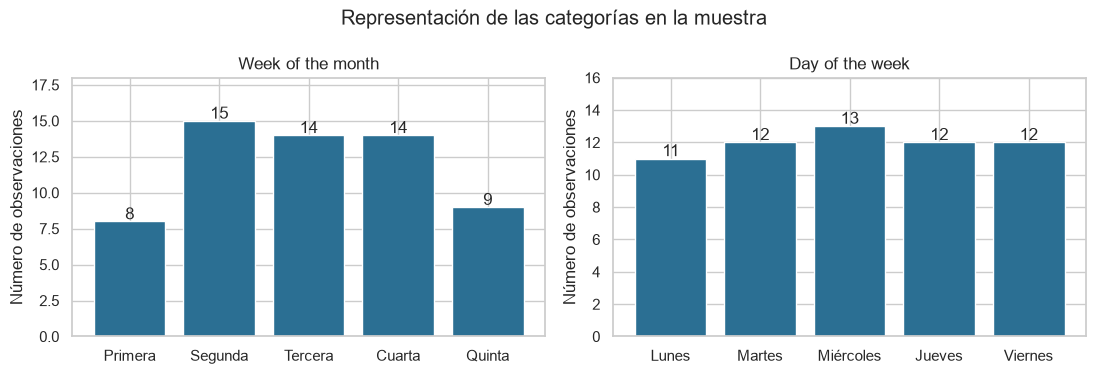

In [4]:
category_labels = {
    "Week of the month": {1: "Primera", 2: "Segunda", 3: "Tercera", 4: "Cuarta", 5: "Quinta"},
    "Day of the week": {2: "Lunes", 3: "Martes", 4: "Miércoles", 5: "Jueves", 6: "Viernes"}
}
frequency_tables = {}
for column, allowed in allowed_values.items():
    counts = df[column].value_counts().reindex(allowed, fill_value=0)
    table = pd.DataFrame({
        "significado": [category_labels[column][code] for code in allowed],
        "frecuencia": counts,
        "porcentaje": 100 * counts / len(df)
    })
    table.index.name = "codigo"
    frequency_tables[column] = table
    print(f"{column} | Valores posibles: {allowed}")
    display(table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, column in zip(axes, cat_cols):
    table = frequency_tables[column]
    ax.bar(table["significado"], table["frecuencia"], color="#2b6f93")
    ax.set(title=column, ylabel="Número de observaciones")
    ax.set_ylim(0, table["frecuencia"].max() + 3)
    for position, count in enumerate(table["frecuencia"]):
        ax.text(position, count + 0.15, str(count), ha="center")
fig.suptitle("Representación de las categorías en la muestra")
fig.tight_layout()
plt.show()

## Variables cuantitativas: estadística descriptiva

`describe().T` organiza una fila por variable. **Media** y **mediana** resumen el centro; **desviación estándar muestral** (`std`, con denominador n−1) resume la dispersión. El **mínimo** y el **máximo** delimitan los valores observados. Q1 y Q3 son los percentiles 25 y 75; su diferencia, el **rango intercuartílico (IQR)**, describe el 50 % central.

La tabla incluye el objetivo y conserva las unidades del archivo. Diferencias grandes de escala entre columnas no prueban, por sí mismas, mayor relevancia predictiva.

In [5]:
stats = df[quant_cols].describe().T.rename(columns={
    "count": "n", "mean": "media", "std": "desviacion_estandar",
    "min": "minimo", "25%": "Q1", "50%": "mediana", "75%": "Q3", "max": "maximo"
})
stats["rango"] = stats["maximo"] - stats["minimo"]
stats["IQR"] = stats["Q3"] - stats["Q1"]
stats["asimetria"] = df[quant_cols].skew()
display(stats.round(3))

,n,media,desviacion_estandar,minimo,Q1,mediana,Q3,maximo,rango,IQR,asimetria
Non-urgent order,60.0,172.555,69.506,43.651,125.348,151.062,194.606,435.304,391.653,69.258,1.546
Urgent order,60.0,118.921,27.171,77.371,100.888,113.114,132.108,223.270,145.899,31.220,1.300
Order type A,60.0,52.112,18.830,21.826,39.456,47.166,58.464,118.178,96.352,19.008,1.724
Order type B,60.0,109.230,50.741,25.125,74.916,99.482,132.171,267.342,242.217,57.255,1.339
Order type C,60.0,139.531,41.443,74.372,113.632,127.990,160.108,302.448,228.076,46.475,1.728
Fiscal sector orders,60.0,77.396,186.502,0.000,1.243,7.832,20.361,865.000,865.000,19.118,3.147
Orders from the traffic controller sector,60.0,44504.350,12197.905,11992.000,34994.250,44312.000,52111.750,71772.000,59780.000,17117.500,0.039
Banking orders (1),60.0,46640.833,45220.736,3452.000,20130.000,32527.500,45118.750,210508.000,207056.000,24988.750,2.043
Banking orders (2),60.0,79401.483,40504.420,16411.000,50680.500,67181.000,94787.750,188411.000,172000.000,44107.250,0.949
Banking orders (3),60.0,23114.633,13148.040,7679.000,12609.750,18011.500,31047.750,73839.000,66160.000,18438.000,1.419


## Distribución de la demanda total

El histograma agrupa la demanda en intervalos; su altura indica cuántos días caen en cada intervalo. Las líneas permiten comparar media y mediana. El diagrama de caja muestra la mediana, el 50 % central y posibles valores extremos según la regla de 1.5 × IQR. Un punto fuera de los bigotes es una señal para investigar, no una justificación automática para borrarlo.

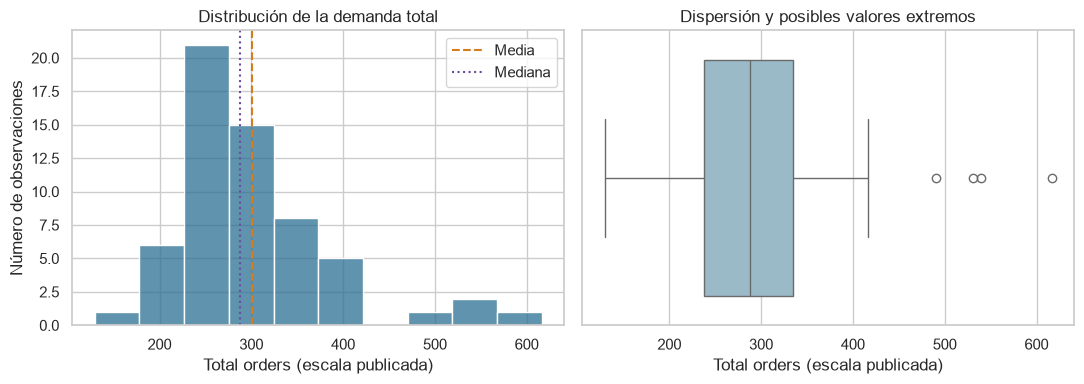

Media: 300.873; mediana: 288.034; mínimo: 129.412; máximo: 616.453


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x=target, bins=10, color="#2b6f93", ax=axes[0])
axes[0].axvline(df[target].mean(), color="#d67c1c", linestyle="--", label="Media")
axes[0].axvline(df[target].median(), color="#694d9f", linestyle=":", label="Mediana")
axes[0].set(title="Distribución de la demanda total", xlabel="Total orders (escala publicada)", ylabel="Número de observaciones")
axes[0].legend()
sns.boxplot(data=df, x=target, color="#93bdd0", ax=axes[1])
axes[1].set(title="Dispersión y posibles valores extremos", xlabel="Total orders (escala publicada)")
fig.tight_layout()
plt.show()
print(f"Media: {df[target].mean():.3f}; mediana: {df[target].median():.3f}; mínimo: {df[target].min():.3f}; máximo: {df[target].max():.3f}")

## Relación entre día de la semana y demanda

Cada caja resume un grupo de días y cada punto representa una observación. La tabla agrega tamaño de muestra, media, mediana y dispersión; así una diferencia entre cajas puede interpretarse junto con el número de datos que la sustenta.

Esta comparación identifica una asociación descriptiva. Con solo 60 observaciones y sin fechas completas no demuestra causalidad, estabilidad futura ni significancia estadística.

,count,mean,median,std,min,max
Lunes,11,390.215,363.402,69.289,316.849,530.944
Martes,12,303.932,277.526,105.233,210.517,616.453
Miércoles,13,281.928,246.992,89.265,188.601,539.577
Jueves,12,273.968,253.306,56.733,202.022,402.607
Viernes,12,263.348,251.402,70.499,129.412,416.830


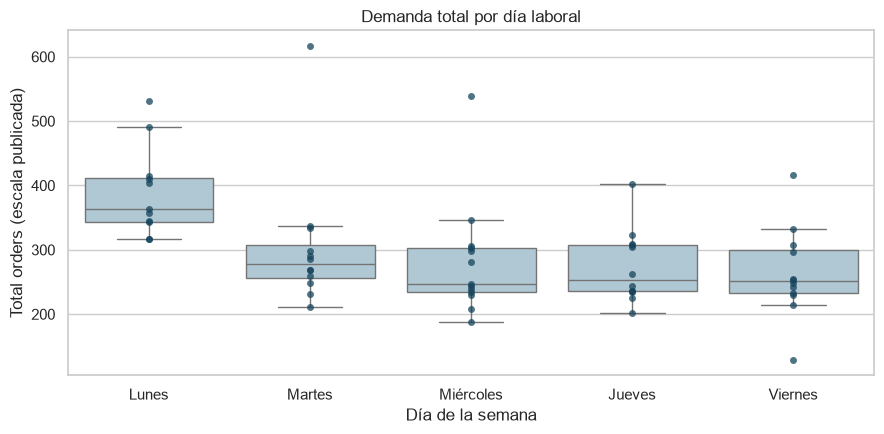

In [7]:
weekday_codes = allowed_values["Day of the week"]
weekday_names = [category_labels["Day of the week"][code] for code in weekday_codes]
weekday_summary = df.groupby("Day of the week")[target].agg(["count", "mean", "median", "std", "min", "max"])
weekday_summary = weekday_summary.reindex(weekday_codes)
weekday_summary.index = weekday_names
display(weekday_summary.round(3))

plot_df = df.copy()
plot_df["Día"] = pd.Categorical(
    plot_df["Day of the week"].map(category_labels["Day of the week"]),
    categories=weekday_names, ordered=True
)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=plot_df, x="Día", y=target, order=weekday_names, color="#a9cbd9", showfliers=False, ax=ax)
# jitter=False mantiene la figura reproducible y cada punto representa un día.
sns.stripplot(data=plot_df, x="Día", y=target, order=weekday_names, color="#16445c", size=5, alpha=0.75, jitter=False, ax=ax)
ax.set(title="Demanda total por día laboral", ylabel="Total orders (escala publicada)", xlabel="Día de la semana")
fig.tight_layout()
plt.show()

## Relación aritmética con el objetivo y riesgo de fuga de información

Antes de interpretar una correlación como capacidad predictiva, comprobamos si algunas variables son componentes del propio resultado. Comparamos la suma de los tipos A, B y C con la demanda total del mismo registro. `np.isclose` usa una pequeña tolerancia porque la aritmética de punto flotante puede producir residuos diminutos.

En esta copia, los tres componentes reconstruyen el total en las 60 filas. Para predecir demanda futura, emplearlos sería una fuga de información si sus cantidades reales solo se conocen al finalizar el día. Hay que definir el momento del pronóstico y verificar la disponibilidad de cada predictor. Esta comprobación explica la relación; no entrena un modelo.

Total = A + B + C: 60 de 60 registros
Diferencia absoluta máxima: 5.684e-14


,Total orders,A + B + C,residuo
0,539.577,539.577,0.0
1,224.675,224.675,0.0
2,129.412,129.412,0.0
3,317.120,317.120,0.0
4,210.517,210.517,0.0


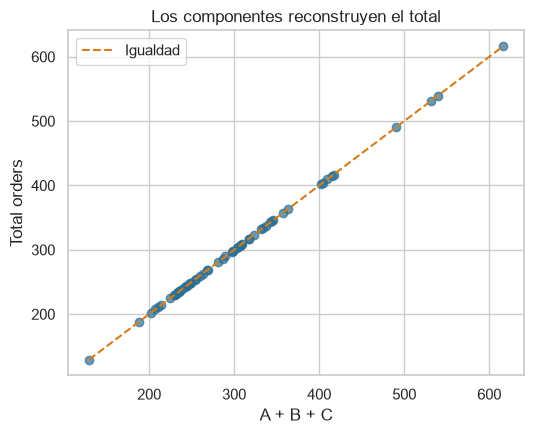

In [8]:
components = ["Order type A", "Order type B", "Order type C"]
component_sum = df[components].sum(axis=1)
residual = df[target] - component_sum
matches = np.isclose(df[target], component_sum, rtol=0, atol=1e-9)
print(f"Total = A + B + C: {int(matches.sum())} de {len(df)} registros")
print(f"Diferencia absoluta máxima: {residual.abs().max():.3e}")
display(pd.DataFrame({"Total orders": df[target], "A + B + C": component_sum, "residuo": residual}).head())

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(component_sum, df[target], color="#2b6f93", alpha=0.7)
limits = [min(component_sum.min(), df[target].min()), max(component_sum.max(), df[target].max())]
ax.plot(limits, limits, "--", color="#d67c1c", label="Igualdad")
ax.set(title="Los componentes reconstruyen el total", xlabel="A + B + C", ylabel="Total orders")
ax.legend()
fig.tight_layout()
plt.show()

## Escala del sector fiscal: cuestión de calidad pendiente

Como diagnóstico adicional, comparamos `Total orders` con la suma de pedidos urgentes, no urgentes y fiscales. Las discrepancias pueden revelar problemas de formato o de definición; por sí mismas no autorizan una corrección.

Hay 11 filas con discrepancia en la escala recibida. Dividir únicamente sus valores fiscales por 1,000 haría coincidir esa suma con el total, lo que sugiere una hipótesis sobre separadores o escala. Se necesita confirmar las unidades y la definición con la fuente antes de modificar los datos. El notebook conserva todos los valores.

In [9]:
fiscal_sum = df["Non-urgent order"] + df["Urgent order"] + df["Fiscal sector orders"]
fiscal_mismatch = ~np.isclose(df[target], fiscal_sum, rtol=0, atol=1e-9)
print("Registros con discrepancia fiscal:", int(fiscal_mismatch.sum()))
fiscal_review = df.loc[fiscal_mismatch, ["Non-urgent order", "Urgent order", "Fiscal sector orders", target]].copy()
fiscal_review.index = fiscal_review.index + 1
fiscal_review.index.name = "fila_de_datos"
fiscal_review["diferencia_total_menos_suma"] = (df[target] - fiscal_sum).loc[fiscal_mismatch].to_numpy()
display(fiscal_review.round(3))

Registros con discrepancia fiscal: 11


,Non-urgent order,Urgent order,Fiscal sector orders,Total orders,diferencia_total_menos_suma
fila_de_datos,,,,,
6,110.925,96.360,79.0,207.364,-78.921
10,146.518,101.045,865.0,248.428,-864.135
11,178.433,102.793,194.0,281.420,-193.806
20,131.067,166.649,844.0,298.560,-843.156
21,130.129,98.927,193.0,229.249,-192.807
31,206.206,92.160,93.0,298.459,-92.907
34,235.106,110.874,55.0,346.035,-54.945
38,221.438,111.392,529.0,333.359,-528.471
39,193.957,111.859,540.0,306.356,-539.460


## Lectura del EDA

- La copia tiene **60 filas y 13 columnas**, sin faltantes ni duplicados completos; dos variables se analizan como cualitativas y once como cuantitativas, incluido el objetivo.
- La demanda total tiene media **300.873**, mediana **288.0345** y rango observado **129.412–616.453**, en la escala publicada. La media mayor que la mediana y los valores altos justifican examinar la asimetría.
- Los grupos por día laboral tienen entre **11 y 13 observaciones**. Sus diferencias son hallazgos descriptivos de esta muestra.
- Los tipos A/B/C suman el objetivo. Es necesario revisar la disponibilidad temporal de esos datos antes de diseñar un pronóstico.
- El sector fiscal presenta una posible inconsistencia de escala que queda documentada sin modificar el archivo.
- No hay una fecha completa. Se preserva el orden recibido, pero **no se ha verificado que sea cronológico**; no se reconstruyen fechas a partir de semana y día.

El siguiente trabajo deberá definir el instante de predicción, resolver la cuestión de unidades y diseñar una evaluación compatible con el uso esperado. Este notebook finaliza en el EDA.